In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))


# 02 · EDA — qué hay realmente en mis datos

El EDA **no es hacer gráficos**: es descubrir qué decisiones hay que tomar antes de modelar. Este
notebook termina con una **tabla de decisiones**, cada una con una cifra y un motivo.
Los hallazgos y la tabla también se copian a `reports/01_eda.md`.

**Proyecto RiskVision · Grupo 6.** Dataset: *Default of Credit Card Clients* (UCI, CC BY 4.0). Resultados de referencia del
notebook de selección de modelo: `model_selection_classification_REVISION_FINAL.ipynb`.

**Preguntas guía:** (1) unidad de análisis · (2) objetivo · (3) suciedad · (4) qué debería ser estable ·
(5) sospecha de fuga.

## 0. Cargar los datos

In [2]:
import pandas as pd

RAW_DIR = Path.cwd().resolve().parent / "data" / "raw"
files = sorted(p for p in RAW_DIR.glob("*") if p.suffix.lower() in {".csv", ".parquet", ".xlsx", ".xls"})

if not files:
    df = None
    print("Todavía no hay datos. Coloca tu dataset en data/raw/ (csv, parquet, xlsx o xls) y vuelve a ejecutar.")
else:
    path = files[0]
    if path.suffix == ".parquet":
        df = pd.read_parquet(path)
    elif path.suffix in {".xlsx", ".xls"}:
        # El archivo de UCI trae una primera fila auxiliar (X1...X23/Y); los nombres reales están en la segunda.
        df = pd.read_excel(path, header=1)
    else:
        df = pd.read_csv(path, low_memory=False)
    print(f"{path.name}: {df.shape[0]:,} filas x {df.shape[1]} columnas")
    # No hay nombres, documentos ni teléfonos: solo un ID anónimo (se excluye del modelo, no se borra aquí).

ID_COL = "ID"                            # identifica al cliente
TARGET = "default payment next month"    # 1 = incumple el próximo mes, 0 = paga

default of credit card clients.xls: 30,000 filas x 25 columnas


## 1. ¿Cuál es la unidad de análisis? ¿Qué representa una fila?

*Pregunta:* ¿una fila es un cliente, una transacción, un cliente en un mes...? ¿Alguna entidad
aparece en **varias filas**? De eso depende cómo se parte el dato.

In [3]:
if df is None:
    print("Sin datos todavía: esta celda se ejecutará cuando coloques tu dataset en data/raw/.")
else:
    print("filas:", len(df), "| columnas:", df.shape[1])
    if ID_COL:
        print("entidades distintas:", df[ID_COL].nunique())
        print(df.groupby(ID_COL).size().value_counts().head())
    else:
        print("TODO: define ID_COL arriba (la columna que identifica a la entidad) y vuelve a ejecutar.")

filas: 30000 | columnas: 25
entidades distintas: 30000
1    30000
Name: count, dtype: int64


**Mi respuesta (una frase):** Cada fila es un cliente de tarjeta de crédito en un momento dado (límite, datos demográficos, 6 meses de historial de pagos y facturación, y si incumplió el mes siguiente). Los 30.000 `ID` son distintos: ningún cliente se repite.

**Unidad por la que partiré los datos:** por fila, estratificada por la variable objetivo, porque cada fila es un cliente distinto y no hay riesgo de que el mismo cliente quede en entrenamiento y en prueba.

## 2. ¿Cómo está el objetivo?

*Pregunta:* en clasificación, ¿qué porcentaje acierta predecir siempre la clase más frecuente?
¿El objetivo cambia dentro de la misma entidad? ¿Tiene vacíos?

In [4]:
if df is None:
    print("Sin datos todavía: esta celda se ejecutará cuando coloques tu dataset en data/raw/.")
else:
    if TARGET:
        print(df[TARGET].value_counts(normalize=True).head(10))
        print("vacíos en el objetivo:", df[TARGET].isna().sum())
    else:
        print("TODO: define TARGET arriba y vuelve a ejecutar.")

default payment next month
0    0.7788
1    0.2212
Name: proportion, dtype: float64
vacíos en el objetivo: 0


**Hallazgo:** Solo el 22,12 % de los clientes incumple (6.636 de 30.000). Está desbalanceado, pero la clase minoritaria supera el 20 % y no tiene vacíos.

**Línea base (qué resultado obtiene una regla trivial):** decir siempre «paga» acierta el 77,88 % de las veces (exactitud) pero no detecta a ningún cliente que incumple (recall 0 %). Su ROC AUC es 0,5000. Por eso la exactitud no sirve como métrica aquí.

## 3. ¿Qué tan sucios están los datos y de qué manera?

*Preguntas:* ¿hay números guardados como texto? ¿valores centinela? ¿valores imposibles (salto
brusco en los percentiles, negativos)? ¿vacíos? ¿duplicados? ¿datos personales?
Usa los chequeos de la sección 3 de la guía.

In [5]:
if df is None:
    print("Sin datos todavía: esta celda se ejecutará cuando coloques tu dataset en data/raw/.")
else:
    print(df.dtypes.value_counts())
    print("\nvacíos por columna (mayores):")
    print(df.isna().mean().sort_values(ascending=False).head(8).round(3))
    print("\nfilas duplicadas (completas):", df.duplicated().sum())
    print("filas duplicadas ignorando ID:", df.drop(columns=ID_COL).duplicated().sum())

int64    25
Name: count, dtype: int64

vacíos por columna (mayores):
ID           0.0
LIMIT_BAL    0.0
SEX          0.0
EDUCATION    0.0
MARRIAGE     0.0
AGE          0.0
PAY_0        0.0
PAY_2        0.0
dtype: float64

filas duplicadas (completas): 0
filas duplicadas ignorando ID: 35


In [6]:
if df is not None:
    # Categorías: ¿hay códigos que no están en la documentación de UCI?
    # Documentado: EDUCATION 1 posgrado, 2 universidad, 3 secundaria, 4 otros | MARRIAGE 1 casado, 2 soltero, 3 otros
    for col in ["EDUCATION", "MARRIAGE", "SEX"]:
        t = df.groupby(col)[TARGET].agg(clientes="size", tasa_incumplimiento="mean").round(3)
        print(f"--- {col} ---"); display(t)
    print("EDUCATION con código 0, 5 o 6 (sin documentar):", df["EDUCATION"].isin([0, 5, 6]).sum(), "clientes")
    print("MARRIAGE con código 0 (sin documentar):", (df["MARRIAGE"] == 0).sum(), "clientes")

--- EDUCATION ---


,clientes,tasa_incumplimiento
EDUCATION,,
0,14,0.000
1,10585,0.192
2,14030,0.237
3,4917,0.252
4,123,0.057
5,280,0.064
6,51,0.157


--- MARRIAGE ---


,clientes,tasa_incumplimiento
MARRIAGE,,
0,54,0.093
1,13659,0.235
2,15964,0.209
3,323,0.260


--- SEX ---


,clientes,tasa_incumplimiento
SEX,,
1,11888,0.242
2,18112,0.208


EDUCATION con código 0, 5 o 6 (sin documentar): 345 clientes
MARRIAGE con código 0 (sin documentar): 54 clientes


In [7]:
if df is not None:
    # Historial de pagos: -2, -1 y 0 son estados (sin consumo, pagó todo, pago mínimo); 1..8 = meses de atraso
    pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
    display(pd.concat({c: df[c].value_counts().sort_index() for c in pay_cols}, axis=1).fillna(0).astype(int))
    print("Tasa de incumplimiento según PAY_0 (estado de septiembre):")
    display(df.groupby("PAY_0")[TARGET].mean().round(3).to_frame("tasa_incumplimiento"))

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


Tasa de incumplimiento según PAY_0 (estado de septiembre):


,tasa_incumplimiento
PAY_0,
-2,0.132
-1,0.168
0,0.128
1,0.339
2,0.691
3,0.758
4,0.684
5,0.500
6,0.545


In [8]:
if df is not None:
    # Montos: negativos, ceros y colas largas
    bill = [f"BILL_AMT{i}" for i in range(1, 7)]
    pay_amt = [f"PAY_AMT{i}" for i in range(1, 7)]
    print("Clientes con algún BILL_AMT negativo:", (df[bill] < 0).any(axis=1).sum(), f"({(df[bill] < 0).any(axis=1).mean():.2%})")
    print("Clientes con facturación mayor al límite en algún mes:", df[bill].gt(df["LIMIT_BAL"], axis=0).any(axis=1).sum())
    print("Clientes sin facturación ni pagos en los 6 meses:", ((df[bill] == 0).all(axis=1) & (df[pay_amt] == 0).all(axis=1)).sum())
    q = df[pay_amt].describe(percentiles=[.5, .99]).loc[["50%", "99%", "max"]].round(0)
    display(q)
    print("Edad:", df["AGE"].min(), "a", df["AGE"].max(), "| Límite de crédito:", df["LIMIT_BAL"].min(), "a", df["LIMIT_BAL"].max())

Clientes con algún BILL_AMT negativo: 1930 (6.43%)
Clientes con facturación mayor al límite en algún mes: 3931
Clientes sin facturación ni pagos en los 6 meses: 795


,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
50%,2100.0,2009.0,1800.0,1500.0,1500.0,1500.0
99%,66522.0,76651.0,70000.0,67054.0,65608.0,82619.0
max,873552.0,1684259.0,896040.0,621000.0,426529.0,528666.0


Edad: 21 a 79 | Límite de crédito: 10000 a 1000000


**Hallazgos de calidad (con cifras):**
- **Sin vacíos, sin texto, sin duplicados completos.** Las 25 columnas son enteros. Hay 35 filas idénticas si se ignora el `ID`; es plausible que clientes distintos coincidan, así que no se borran.
- **Categorías sin documentar:** `EDUCATION` tiene los códigos 0 (14), 5 (280) y 6 (51), es decir 345 clientes (1,15 %), más 123 en el código 4 («otros»). `MARRIAGE` tiene el código 0 en 54 clientes.
- **Los estados de pago mezclan dos ideas:** `-2`, `-1` y `0` no son meses de atraso (son estados como «sin consumo» o «pagó todo»; UCI no documenta bien el -2 y el 0) y `1` a `8` sí son meses de atraso. Además la columna `PAY_1` no existe: se salta de `PAY_0` a `PAY_2`.
- **Facturación con negativos:** 1.930 clientes (6,43 %) tienen algún `BILL_AMT` negativo (saldo a favor), así que `log(x)` no sirve.
- **Colas largas en pagos:** por ejemplo `PAY_AMT2` tiene percentil 99 de 76.651 y máximo de 1.684.259.
- **Atípicos plausibles:** 3.931 clientes facturan por encima de su límite en algún mes y 795 no tienen movimiento en 6 meses; son comportamientos reales, no errores.
- **Datos personales:** ninguno (solo un `ID` anónimo). `SEX`, `AGE` y `MARRIAGE` son atributos sensibles.

## 4. ¿Qué variables deberían ser estables y no lo son?

*Pregunta:* ¿qué columnas deberían ser **constantes dentro de una misma entidad** (edad, ocupación,
ingreso, categoría)? ¿Cuántas entidades tienen más de un valor? Si es ruido, ¿cómo lo repararías?
*(Solo aplica si una entidad aparece en varias filas.)*

In [9]:
if df is None:
    print("Sin datos todavía: esta celda se ejecutará cuando coloques tu dataset en data/raw/.")
else:
    print("No aplica: cada cliente aparece en una sola fila (ID únicos:", df[ID_COL].is_unique, ").")

No aplica: cada cliente aparece en una sola fila (ID únicos: True ).


**Hallazgo:** No aplica. Como ninguna entidad se repite, no hay variables que deban ser constantes dentro de una misma entidad (edad, sexo, etc.) y comprobarlo.

**¿Ruido o cambio real? ¿Por qué?** No aplica por la misma razón.

## 5. ¿Hay algo que suene a fuga de información?

*Pregunta:* ¿alguna columna contiene la respuesta, o solo se conoce **después** de la decisión que
quieres apoyar? Lista las sospechosas; **no las descartes por intuición**, las mediremos en la etapa 4.

Correlación absoluta con el objetivo (las 6 más altas):
PAY_0    0.325
PAY_2    0.264
PAY_3    0.235
PAY_4    0.217
PAY_5    0.204
PAY_6    0.187
Name: default payment next month, dtype: float64


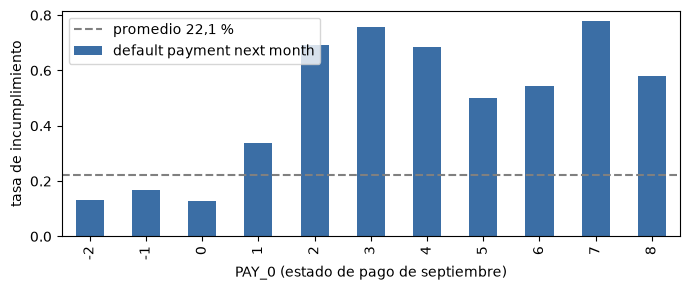

In [10]:
if df is None:
    print("Sin datos todavía: esta celda se ejecutará cuando coloques tu dataset en data/raw/.")
else:
    import matplotlib.pyplot as plt
    corr = df.drop(columns=ID_COL).corr()[TARGET].drop(TARGET)
    print("Correlación absoluta con el objetivo (las 6 más altas):")
    print(corr.abs().sort_values(ascending=False).head(6).round(3))
    rates = df.groupby("PAY_0")[TARGET].mean()
    ax = rates.plot(kind="bar", color="#3b6ea5", figsize=(7, 3))
    ax.axhline(df[TARGET].mean(), color="gray", ls="--", label="promedio 22,1 %")
    ax.set_ylabel("tasa de incumplimiento"); ax.set_xlabel("PAY_0 (estado de pago de septiembre)"); ax.legend()
    plt.tight_layout(); plt.show()

**Columnas sospechosas de fuga y por qué:** No encontramos una fuga evidente. Las columnas `PAY_*`, `BILL_AMT*` y `PAY_AMT*` cubren abril a septiembre, antes del mes que se predice. La más fuerte es `PAY_0` (estado de septiembre, correlación 0,33): quien ya lleva 2 o más meses de atraso incumple el 69 % de las veces o más, frente al 13–17 % de quien va al día. Es un predictor legítimo pero dominante: se medirá el modelo con y sin ella en la etapa 4 para saber cuánto depende de una sola columna. El riesgo de fuga está en el proceso (escalar, imputar o elegir el umbral con datos de prueba), no en las columnas.

## 6. Tabla de decisiones (entregable del EDA)

| # | Hallazgo (con cifra) | Decisión | Motivo |
|---|---|---|---|
| 1 | 30.000 `ID` distintos: ningún cliente se repite | Partir por fila (80/20, estratificado, semilla 42) y excluir `ID` del modelo | No hay riesgo de que un cliente quede en entrenamiento y prueba; `ID` no describe comportamiento |
| 2 | 22,12 % incumple; la regla «siempre paga» acierta 77,88 % con recall 0 % | Estratificar las particiones y usar ROC AUC (más recall y AUC-PR de control), no la exactitud | La exactitud premia no detectar a nadie; el error caro es el falso negativo |
| 3 | `EDUCATION` 0, 5 y 6 suman 345 clientes (1,15 %) y `MARRIAGE` 0 son 54, sin documentar | Agrupar esos códigos en «otros» (4 y 3) antes de codificar, dentro del pipeline | Categorías sin significado conocido; agruparlas evita categorías casi vacías |
| 4 | `PAY_*` mezcla estados (-2, -1, 0) con meses de atraso (1 a 8); la tasa de incumplimiento sube de 13–17 % a 69 % o más desde 2 meses de atraso | Conservarlas como numéricas ordenadas y probar una variable «atraso ≥ 2» en la etapa de features | Contienen la señal más fuerte; el orden numérico respeta el aumento del riesgo |
| 5 | 1.930 clientes (6,43 %) con `BILL_AMT` negativo; `PAY_AMT2` va de percentil 99 = 76.651 a máximo = 1.684.259 | No aplicar `log(x)`; mantener los montos en escala original y comparar `log1p` o Yeo-Johnson dentro del pipeline | Hay negativos y ceros; solo se acepta una transformación si mejora por validación cruzada |
| 6 | Mujeres incumplen 20,8 % y hombres 24,2 %; `AGE` y `MARRIAGE` también separan grupos | Revisar errores por grupo y probar el modelo con y sin `SEX` | Atributos sensibles: el modelo no debe discriminar |
| 7 | `PAY_0` es la variable más correlacionada con el objetivo (0,33) | Medir el modelo con y sin `PAY_0` en la etapa 4 | Verificar que el modelo no dependa de una sola columna |
| 8 | 35 filas idénticas ignorando `ID`; 3.931 clientes facturan por encima del límite | No borrar filas | Parecen clientes reales distintos; el volumen perdido sería mínimo y arriesgado |

## Entregable de esta etapa

- [x] Este notebook ejecuta de principio a fin.
- [x] La tabla de decisiones tiene **al menos 5** filas con cifra y motivo.
- [x] `reports/01_eda.md` está actualizado.
- [x] Declaré mi **unidad de análisis** por escrito.

**Siguiente:** `03_preprocesamiento.ipynb`.